## Computer Vision Project (Phase 2)

# Part 1 (Noise Classifier)

## Imports

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset

from torchvision import transforms
import torchvision.models as models
from PIL import Image

from torchmetrics import Accuracy
from tqdm import tqdm

from sklearn.model_selection import train_test_split
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, classification_report

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Utils & Functions

In [2]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'

In [3]:
class AverageMeter(object):
    """Computes and stores the average and current value"""
    def __init__(self):
        self.reset()

    def reset(self):
        self.val = 0
        self.avg = 0
        self.sum = 0
        self.count = 0

    def update(self, val, n=1):
        self.val = val
        self.sum += val * n
        self.count += n
        self.avg = self.sum / self.count

In [5]:
seed = 0

def set_seed(seed):
  np.random.seed(seed)
  torch.manual_seed(seed)
  if torch.cuda.is_available():
      torch.cuda.manual_seed(seed)

In [6]:
def train_one_epoch(model, train_loader, loss_fn, optimizer, epoch=None):
    model.train()
    loss_train = AverageMeter()
    acc_train = Accuracy(task="multiclass", num_classes=3).to(device)
    with tqdm(train_loader, unit="batch") as tepoch:
        for inputs, targets in tepoch:
            if epoch is not None:
                tepoch.set_description(f"Epoch {epoch}")
            inputs = inputs.to(device)
            targets = targets.to(device)
            
            optimizer.zero_grad()

            outputs = model(inputs)
      
            loss = loss_fn(outputs, targets)

            loss.backward()
            optimizer.step()

            loss_train.update(loss.item())
            acc_train(outputs, targets.int())
            tepoch.set_postfix(loss=loss_train.avg, accuracy=100.*acc_train.compute().item())
    return model, loss_train.avg, acc_train.compute().item()

In [5]:
def validation(model, test_loader, loss_fn):
    model.eval()
    with torch.no_grad():
        loss_valid = AverageMeter()
        acc_valid = Accuracy(task="multiclass", num_classes=3).to(device)
        for i, (inputs, targets) in enumerate(test_loader):
            inputs = inputs.to(device)
            targets = targets.to(device)

            outputs = model(inputs)
            loss = loss_fn(outputs, targets)
      
            loss_valid.update(loss.item())
            acc_valid(outputs, targets.int())
    return loss_valid.avg, acc_valid.compute().item()

In [6]:
def normalize_image(image):
    image_min = image.min()
    image_max = image.max()
    image.clamp_(min = image_min, max = image_max)
    image.add_(-image_min).div_(image_max - image_min + 1e-5)
    return image

def plot_images(images, labels, normalize=True):
    n_images = len(images)

    rows = int(np.sqrt(n_images))
    cols = int(np.sqrt(n_images))

    fig = plt.figure(figsize=(10, 10))

    for i in range(rows*cols):

        ax = fig.add_subplot(rows, cols, i+1)
    
        image = images[i]
        if normalize:
            image = normalize_image(image)

        ax.imshow(image.permute(1, 2, 0).cpu().numpy(), cmap='gray')
        ax.set_title(labels[i])
        ax.axis('off')

In [7]:
def num_params(model):
    nums = sum(p.numel() for p in model.parameters() if p.requires_grad)/1e6
    return nums

In [8]:
def specificity(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    specificity_per_class = {}
    for i in range(3):
        tn = cm[i, i]
        fp = np.sum(cm[:, i]) - tn
        specificity_per_class[i] = tn / (tn + fp)
    return specificity_per_class

In [ ]:
def evaluate(model, loader):
    model.eval()

    all_preds = []
    all_labels = []

    for inputs, labels in loader:
        inputs, labels = inputs.to(device), labels.to(device)
        with torch.no_grad():
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    all_preds = np.array(all_preds)
    all_labels = np.array(all_labels)

    ConfusionMatrixDisplay.from_predictions(all_preds, all_labels)
    print(classification_report(all_preds, all_labels))
    print('Specificity', specificity(all_labels, all_preds))

## Dataset

In [ ]:
class ImageDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.transform = transform
        self.labels = dataframe['Noise Type'].replace({'Gaussian' : 0, 'Salt' : 1, 'Periodic' : 2})#.reset_index()
        self.image_list = dataframe['Noisy Image']#.reset_index()

    def __getitem__(self, item):
        img = Image.open(f'./datasets/DataSet2/{self.image_list.iloc[item]}').convert('RGB')
        label = self.labels.iloc[item]
        if self.transform:
            img = self.transform(img)
        return img, label
        
    def __len__(self):
        return len(self.labels)

In [ ]:
df = pd.read_excel('./datasets/Labels.xlsx')
train_df, test_df = train_test_split(df, test_size=0.15, random_state=0, stratify=df['Noise Type'])
train_df, valid_df = train_test_split(train_df, test_size=0.10, random_state=0, stratify=train_df['Noise Type'])

In [12]:
train_df

,Denoise Image,Noise Type,Noisy Image
354,Without-Noise/cast_def_0_4590.jpeg,Periodic,With-Noise/cast_def_0_4590.jpeg
604,Without-Noise/cast_def_0_7750.jpeg,Salt,With-Noise/cast_def_0_7750.jpeg
107,Without-Noise/cast_def_0_1157.jpeg,Gaussian,With-Noise/cast_def_0_1157.jpeg
449,Without-Noise/cast_def_0_5767.jpeg,Periodic,With-Noise/cast_def_0_5767.jpeg
829,Without-Noise/cast_ok_0_1665.jpeg,Gaussian,With-Noise/cast_ok_0_1665.jpeg
...,...,...,...
525,Without-Noise/cast_def_0_6898.jpeg,Salt,With-Noise/cast_def_0_6898.jpeg
199,Without-Noise/cast_def_0_2480.jpeg,Gaussian,With-Noise/cast_def_0_2480.jpeg
1134,Without-Noise/cast_ok_0_7411.jpeg,Salt,With-Noise/cast_ok_0_7411.jpeg
419,Without-Noise/cast_def_0_5322.jpeg,Periodic,With-Noise/cast_def_0_5322.jpeg


## Models

### ResNet

#### Dataset

In [ ]:
set_seed(seed)
train_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(60),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.55, 0.55, 0.55], std=[0.22, 0.22, 0.22])])

test_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.55, 0.55, 0.55], std=[0.22, 0.22, 0.22])])

In [ ]:
set_seed(seed)
train_set = ImageDataset(train_df, transform=train_transform)
valid_set = ImageDataset(valid_df, transform=test_transform)
test_set = ImageDataset(test_df, transform=test_transform)

In [ ]:
set_seed(seed)
train_loader = DataLoader(train_set, batch_size=64, shuffle=True)
valid_loader = DataLoader(valid_set, batch_size=256, shuffle=True)
test_loader = DataLoader(test_set, batch_size=256, shuffle=False)

In [24]:
print(train_loader.dataset.image_list.shape)
print(valid_loader.dataset.image_list.shape)
print(test_loader.dataset.image_list.shape)

(955,)
(107,)
(188,)


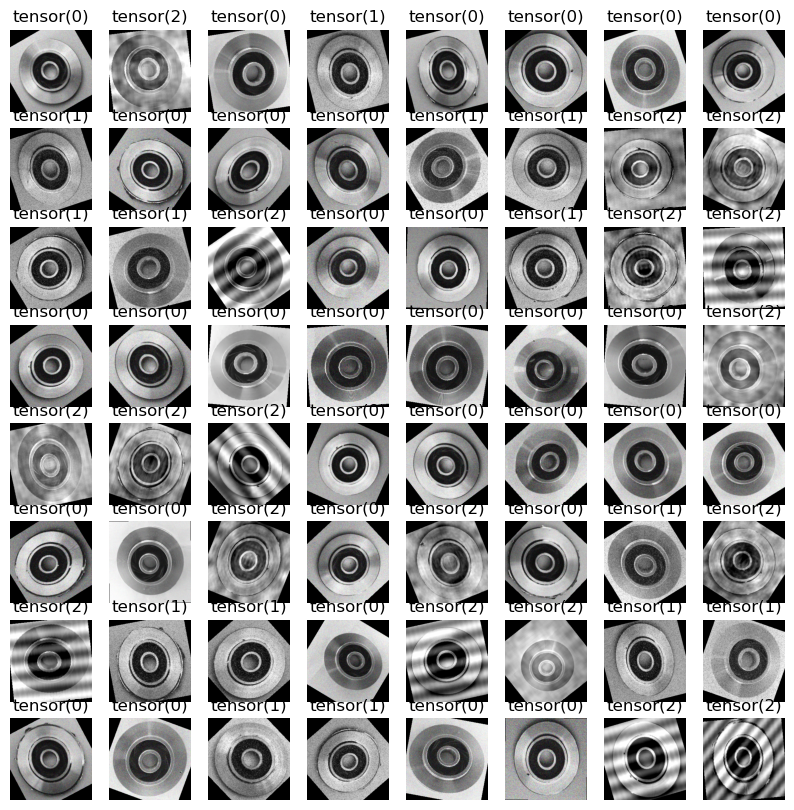

In [25]:
batch = next(iter(train_loader))
plot_images(batch[0], batch[1])

#### Architecture

In [ ]:
set_seed(seed)
def resnet():
    network = models.resnet18(weights='DEFAULT')
    network.fc = nn.Linear(512,3)
    network.requires_grad_(False)
    network.fc.requires_grad_(True)
    
    return network

model = resnet().to(device)

num_params(model)

0.001539

#### Training

In [28]:
loss_train_hist = []
loss_valid_hist = []

acc_train_hist = []
acc_valid_hist = []

best_loss_valid = torch.inf
epoch_counter = 0

In [ ]:
set_seed(seed)
loss_fn = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

In [ ]:
set_seed(seed)

num_epochs = 1

for epoch in range(num_epochs):
  
  model, loss_train, acc_train = train_one_epoch(model, train_loader, loss_fn, optimizer, epoch)

  loss_valid, acc_valid = validation(model, valid_loader, loss_fn)
  
  loss_train_hist.append(loss_train)
  loss_valid_hist.append(loss_valid)

  acc_train_hist.append(acc_train)
  acc_valid_hist.append(acc_valid)
  
  if loss_valid < best_loss_valid:
    torch.save(model, f'./models/Phase 2 Resnet.pt')
    best_loss_valid = loss_valid

  print(f'Valid: Loss = {loss_valid:.4}, Acc = {acc_valid:.4}')
  print()

  epoch_counter += 1

Epoch 0: 100%|██████████████████████████████████████████| 15/15 [00:16<00:00,  1.08s/batch, accuracy=99.8, loss=0.0299]


Valid: Loss = 0.02349, Acc = 1.0



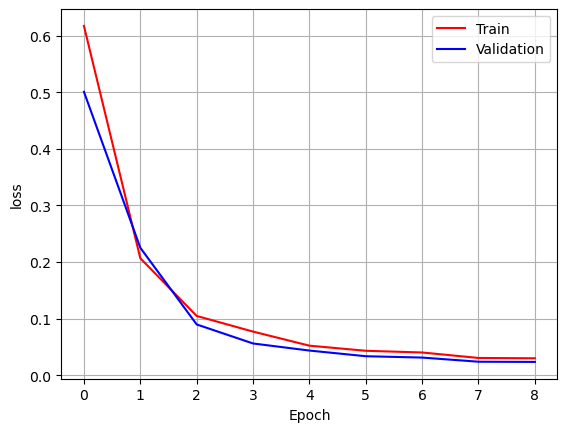

In [49]:
plt.plot(range(epoch_counter), loss_train_hist, 'r-', label='Train')
plt.plot(range(epoch_counter), loss_valid_hist, 'b-', label='Validation')

plt.xlabel('Epoch')
plt.ylabel('loss')
plt.grid(True)
plt.legend()

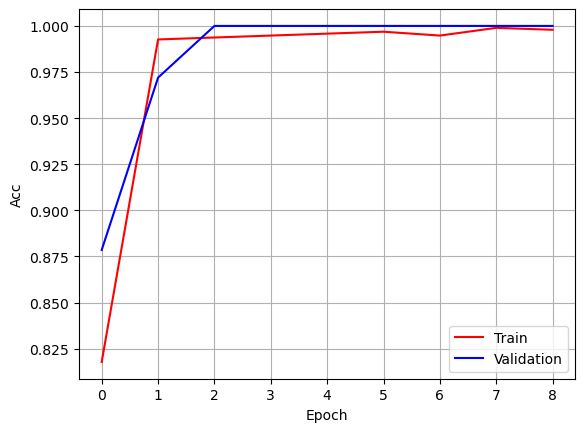

In [50]:
plt.plot(range(epoch_counter), acc_train_hist, 'r-', label='Train')
plt.plot(range(epoch_counter), acc_valid_hist, 'b-', label='Validation')

plt.xlabel('Epoch')
plt.ylabel('Acc')
plt.grid(True)
plt.legend()

#### Evaluation

In [ ]:
model = torch.load('./models/Phase 2 Resnet.pt')

              precision    recall  f1-score   support

           0       1.00      1.00      1.00       306
           1       1.00      1.00      1.00       306
           2       1.00      1.00      1.00       343

    accuracy                           1.00       955
   macro avg       1.00      1.00      1.00       955
weighted avg       1.00      1.00      1.00       955

Specificity {0: 1.0, 1: 1.0, 2: 1.0}


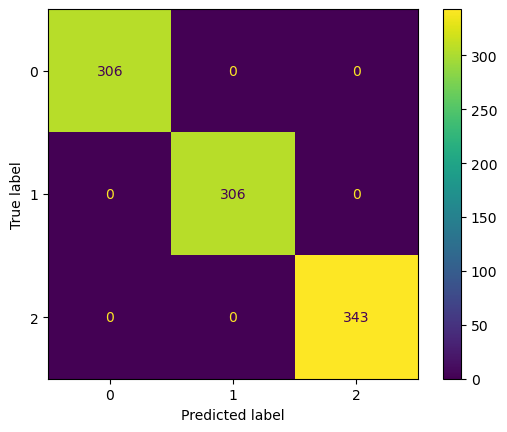

In [22]:
evaluate(model, train_loader)

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        34
           1       1.00      1.00      1.00        34
           2       1.00      1.00      1.00        39

    accuracy                           1.00       107
   macro avg       1.00      1.00      1.00       107
weighted avg       1.00      1.00      1.00       107

Specificity {0: 1.0, 1: 1.0, 2: 1.0}


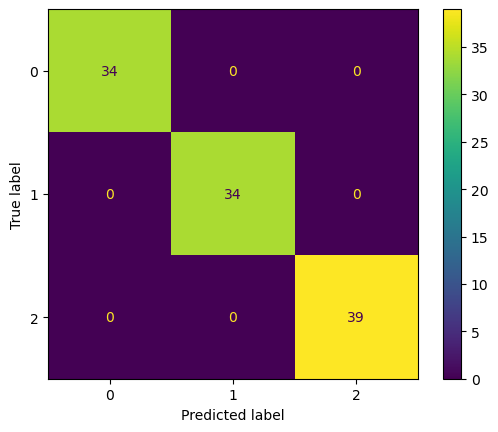

In [23]:
evaluate(model, valid_loader)

              precision    recall  f1-score   support

           0       0.98      1.00      0.99        59
           1       1.00      1.00      1.00        60
           2       1.00      0.99      0.99        69

    accuracy                           0.99       188
   macro avg       0.99      1.00      0.99       188
weighted avg       0.99      0.99      0.99       188

Specificity {0: 1.0, 1: 1.0, 2: 0.9855072463768116}


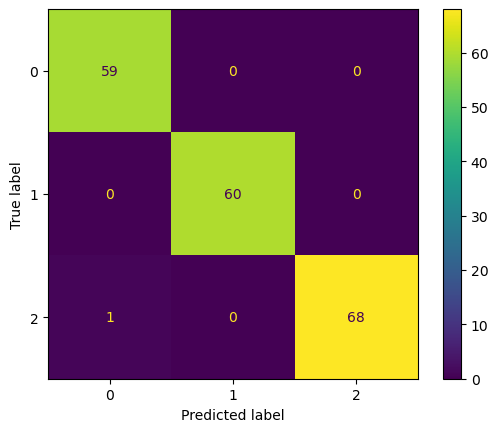

In [24]:
evaluate(model, test_loader)

### ViT

#### Dataset

In [ ]:
set_seed(seed)
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(60),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.55, 0.55, 0.55], std=[0.22, 0.22, 0.22])])

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.55, 0.55, 0.55], std=[0.22, 0.22, 0.22])])

In [ ]:
set_seed(seed)
train_set = ImageDataset(train_df, transform=train_transform)
valid_set = ImageDataset(valid_df, transform=test_transform)
test_set = ImageDataset(test_df, transform=test_transform)

train_loader = DataLoader(train_set, batch_size=64, shuffle=True)
valid_loader = DataLoader(valid_set, batch_size=128, shuffle=False)
test_loader = DataLoader(test_set, batch_size=128, shuffle=False)

#### Architecture

In [ ]:
set_seed(seed)
def ViT():
    network = models.vit_b_16(weights='ViT_B_16_Weights.IMAGENET1K_V1')
    network.heads.head = nn.Linear(768, 3)
    network.requires_grad_(False)
    network.heads.requires_grad_(True)
    
    return network

model = ViT().to(device)
num_params(model)

0.002307

#### Training

In [ ]:
set_seed(seed)
loss_fn = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

In [59]:
loss_train_hist = []
loss_valid_hist = []

acc_train_hist = []
acc_valid_hist = []

best_loss_valid = torch.inf
epoch_counter = 0

In [ ]:
set_seed(seed)

num_epochs = 2

for epoch in range(num_epochs):

  model, loss_train, acc_train = train_one_epoch(model, train_loader, loss_fn, optimizer, epoch)

  loss_valid, acc_valid = validation(model, valid_loader, loss_fn)

  loss_train_hist.append(loss_train)
  loss_valid_hist.append(loss_valid)

  acc_train_hist.append(acc_train)
  acc_valid_hist.append(acc_valid)

  if loss_valid < best_loss_valid:
    torch.save(model, f'./models/Phase 2 Model Vit 100.pt')
    best_loss_valid = loss_valid

  print(f'Valid: Loss = {loss_valid:.4}, Acc = {acc_valid:.4}')
  print()

  epoch_counter += 1

Epoch 0: 100%|██████████████████████████████████████████| 15/15 [00:48<00:00,  3.24s/batch, accuracy=99.9, loss=0.0376]


Valid: Loss = 0.0241, Acc = 1.0



Epoch 1: 100%|███████████████████████████████████████████| 15/15 [00:50<00:00,  3.39s/batch, accuracy=100, loss=0.0268]


Valid: Loss = 0.01892, Acc = 1.0



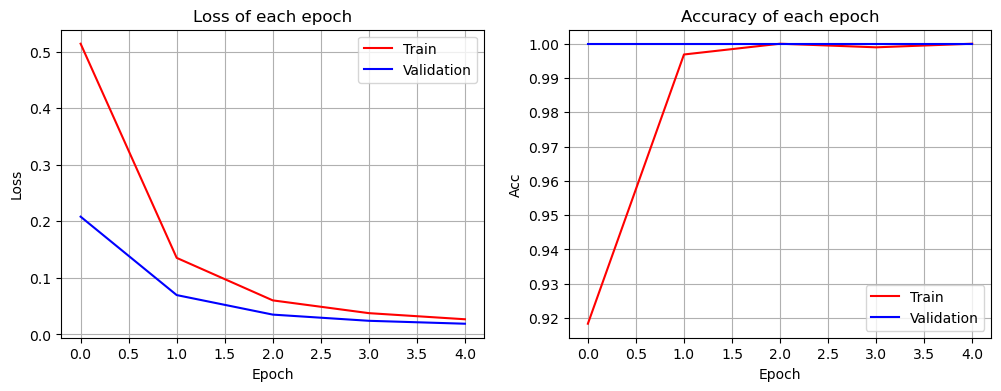

In [66]:
plt.figure(figsize=(12,4))

plt.subplot(1, 2, 1)
plt.plot(range(epoch_counter), loss_train_hist, 'r-', label='Train')
plt.plot(range(epoch_counter), loss_valid_hist, 'b-', label='Validation')
plt.title('Loss of each epoch')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid(True)
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(range(epoch_counter), acc_train_hist, 'r-', label='Train')
plt.plot(range(epoch_counter), acc_valid_hist, 'b-', label='Validation')
plt.title('Accuracy of each epoch')
plt.xlabel('Epoch')
plt.ylabel('Acc')
plt.grid(True)
plt.legend()

#### Evaluation

In [ ]:
model = torch.load('./models/Phase 2 Model Vit 100.pt')

c:\Users\kamya\anaconda3\Lib\site-packages\torch\nn\modules\activation.py:1196: UserWarning: 1Torch was not compiled with flash attention. (Triggered internally at C:\cb\pytorch_1000000000000\work\aten\src\ATen\native\transformers\cuda\sdp_utils.cpp:263.)
  return torch._native_multi_head_attention(


              precision    recall  f1-score   support

           0       1.00      1.00      1.00       306
           1       1.00      1.00      1.00       306
           2       1.00      1.00      1.00       343

    accuracy                           1.00       955
   macro avg       1.00      1.00      1.00       955
weighted avg       1.00      1.00      1.00       955

Specificity {0: 1.0, 1: 1.0, 2: 1.0}


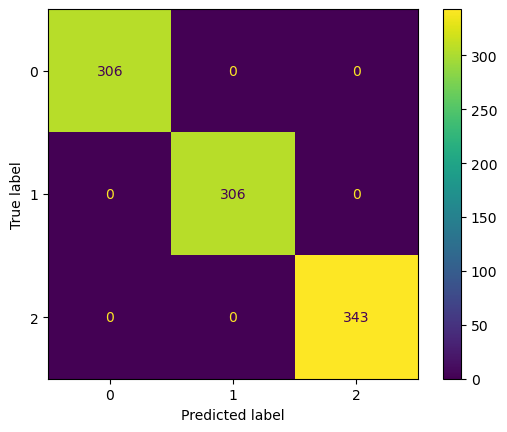

In [30]:
evaluate(model, train_loader)

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        34
           1       1.00      1.00      1.00        34
           2       1.00      1.00      1.00        39

    accuracy                           1.00       107
   macro avg       1.00      1.00      1.00       107
weighted avg       1.00      1.00      1.00       107

Specificity {0: 1.0, 1: 1.0, 2: 1.0}


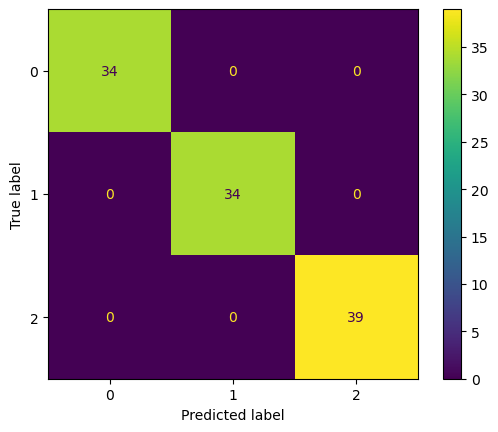

In [31]:
evaluate(model, valid_loader)

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        60
           1       1.00      1.00      1.00        60
           2       1.00      1.00      1.00        68

    accuracy                           1.00       188
   macro avg       1.00      1.00      1.00       188
weighted avg       1.00      1.00      1.00       188

Specificity {0: 1.0, 1: 1.0, 2: 1.0}


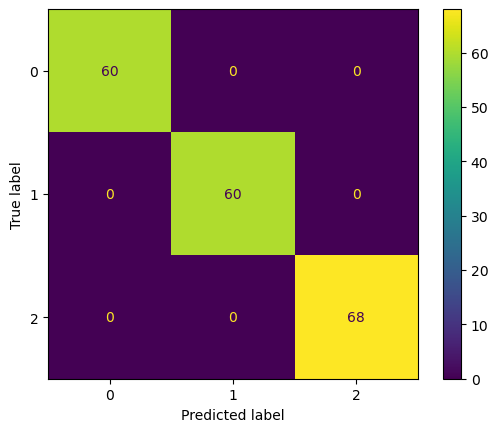

In [32]:
evaluate(model, test_loader)

# Part 2 (Denoiser)

## Imports

In [ ]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import bm3d
from skimage.metrics import structural_similarity as ssim
import lpips

import torch
import torch.nn as nn

from torchvision import transforms

import random

import os

import warnings
warnings.filterwarnings("ignore")

## Periodic AutoEncoder Architecture

In [3]:
class ConvBlock(nn.Module):

    def __init__(self, in_channels, out_channels):
        super(ConvBlock, self).__init__()

        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class PeriodicAutoencoder(nn.Module):

    def __init__(self):
        super(PeriodicAutoencoder, self).__init__()

        # Encoder
        self.encoder1 = ConvBlock(1, 64)
        self.encoder2 = ConvBlock(64, 128)
        self.encoder3 = ConvBlock(128, 256)
        self.encoder4 = ConvBlock(256, 512)

        self.pool = nn.MaxPool2d(2)

        # Bottleneck
        self.bottleneck = ConvBlock(512, 1024)

        # Decoder
        self.up4 = nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False)
        self.decoder4 = ConvBlock(1024 + 512, 512)

        self.up3 = nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False)
        self.decoder3 = ConvBlock(512 + 256, 256)

        self.up2 = nn.Upsample( scale_factor=2, mode="bilinear", align_corners=False)
        self.decoder2 = ConvBlock(256 + 128, 128)

        self.up1 = nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False)
        self.decoder1 = ConvBlock(128 + 64, 64)

        self.output = nn.Conv2d(64, 1, kernel_size=3, padding=1)

    def forward(self, x):

        # Encoder
        e1 = self.encoder1(x)
        e2 = self.encoder2(self.pool(e1))
        e3 = self.encoder3(self.pool(e2))
        e4 = self.encoder4(self.pool(e3))

        # Bottleneck
        b = self.bottleneck(self.pool(e4))

        # Decoder
        d4 = self.up4(b)
        d4 = torch.cat([d4, e4], dim=1)
        d4 = self.decoder4(d4)

        d3 = self.up3(d4)
        d3 = torch.cat([d3, e3], dim=1)
        d3 = self.decoder3(d3)

        d2 = self.up2(d3)
        d2 = torch.cat([d2, e2], dim=1)
        d2 = self.decoder2(d2)

        d1 = self.up1(d2)
        d1 = torch.cat([d1, e1], dim=1)
        d1 = self.decoder1(d1)

        output = torch.sigmoid(self.output(d1))

        return output

## Load Models Needed

In [4]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'

classifier_model = torch.load('./models/Phase 2 Model Vit 100.pt')
classifier_model.to(device)
classifier_model.eval()

periodic_model = PeriodicAutoencoder().to(device)
periodic_model.load_state_dict(torch.load('./models/Periodic_Autoencoder/best_periodic_autoencoder.pt', map_location=device, weights_only=True))
periodic_model.eval()

preprocess = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.55, 0.55, 0.55], std=[0.22, 0.22, 0.22])])

## Define Denoiser Functions

In [18]:
def gaussian_denoiser(image, c=30):
    return bm3d.bm3d(image, c)

def salt_and_pepper_denoiser(image):
    first = cv2.medianBlur(image, 3)
    second = cv2.medianBlur(first, 3)
    return second

# def freq_to_spatial(img):
#     return np.abs(np.fft.ifft2(np.fft.ifftshift(img)))

# def zero_surrounding_pixels(image):
#     modified_image = np.copy(image)
#     rows, cols = image.shape
#     for i in range(rows):
#         for j in range(cols):
#             if image[i, j] == 0:
#                 for di in range(-1, 2):
#                     for dj in range(-1, 2):
#                         if 0 <= i + di < rows and 0 <= j + dj < cols:
#                             modified_image[i + di, j + dj] = 0

#     return modified_image

# def periodic_denoiser(image, i=3, zero_surrounding=False):
#     image = np.array(image)
#     image_fft = np.fft.fft2(image)
#     image_shift = np.fft.fftshift(image_fft)
#     image_magnitude = np.abs(image_shift)
    
#     flat_arr = image_magnitude.flatten()
#     image_shift = image_shift.flatten()
#     max_indices = np.argsort(flat_arr)[-i:]

#     image_shift[max_indices[:-1]] = 0
    
#     final_image = image_shift.reshape(image.shape)
#     if zero_surrounding:
#         final_image = zero_surrounding_pixels(final_image)

#     return freq_to_spatial(final_image)

def periodic_denoiser(image):

    if len(image.shape) == 3:
        gray_image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    else:
        gray_image = image

    resized_image = cv2.resize( gray_image, (256, 256), interpolation=cv2.INTER_AREA)

    input_tensor = torch.from_numpy(resized_image.astype(np.float32) / 255.0).unsqueeze(0).unsqueeze(0).to(device)

    periodic_model.eval()

    with torch.no_grad():
        output = periodic_model(input_tensor)

    denoised_image = output.squeeze().cpu().numpy()

    denoised_image = np.uint8(np.clip(denoised_image * 255.0, 0, 255))

    denoised_image = cv2.resize(denoised_image, (gray_image.shape[1], gray_image.shape[0]), interpolation=cv2.INTER_LINEAR)

    return denoised_image

In [20]:
def classifier(image):
    image = Image.fromarray(image)
    input_tensor = preprocess(image).unsqueeze(0).to(device)
    with torch.no_grad():
        output = classifier_model(input_tensor)
    predicted_idx = torch.argmax(output, dim=1).item()
    return predicted_idx

def denoiser(image):
    predicted_class = classifier(image)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    if predicted_class == 0:
        return gaussian_denoiser(image), 'Gaussian'
    elif predicted_class == 1:
        return salt_and_pepper_denoiser(image), 'Salt'
    elif predicted_class == 2:
        return periodic_denoiser(image), 'Periodic'

## Define Evaluation Functions

In [19]:
def psnr_calculator(original, image):
    return(cv2.PSNR(original.astype(np.float64), image.astype(np.float64)))

def ssim_calculator(original_img, denoised_img):
    ssim_score = ssim(original_img, denoised_img, data_range=255)
    return ssim_score

alexnet_lpips = lpips.LPIPS(net='alex')

Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [off]
Loading model from: c:\Users\kamya\anaconda3\Lib\site-packages\lpips\weights\v0.1\alex.pth


## Evaluation & Results

In [21]:
def load_images_from_folder_and_denoise(noisy, original, dest):
    """For each image in the folder, this function will denoise the image and save the new image.
        This function also returns a DataFrame which contains different metrics of each image."""
    results = [] 
    for filename in os.listdir(noisy):
        img = cv2.imread(os.path.join(noisy,filename), cv2.IMREAD_COLOR)
        img_orig = cv2.imread(os.path.join(original,filename), cv2.IMREAD_GRAYSCALE)
        if img is not None:
            denoised, noise_type = denoiser(img)
            img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
            psnr_value = psnr_calculator(img_orig, denoised)
            ssim_value = ssim_calculator(img_orig, denoised)
            lpips_value = alexnet_lpips(torch.FloatTensor(img_orig), torch.FloatTensor(denoised)).item()
            cv2.imwrite(os.path.join(dest,filename), denoised)
            result = {
                'Image Name': filename,
                'Noise Type': noise_type, 
                'PSNR': psnr_value,
                'SSIM': ssim_value,
                'LPIPS': lpips_value
            }
            results.append(result)
    return pd.DataFrame(results)

In [22]:
results = load_images_from_folder_and_denoise('./datasets/DataSet2/With-Noise/', './datasets/DataSet2/Without-Noise/', './datasets/DataSet2/Denoised/')

In [23]:
results

,Image Name,Noise Type,PSNR,SSIM,LPIPS
0,cast_def_0_0.jpeg,Gaussian,34.068858,0.918113,0.034062
1,cast_def_0_100.jpeg,Gaussian,32.435512,0.885631,0.037462
2,cast_def_0_1015.jpeg,Gaussian,33.311068,0.902477,0.041488
3,cast_def_0_102.jpeg,Gaussian,32.524521,0.898760,0.041026
4,cast_def_0_1046.jpeg,Gaussian,36.951383,0.931655,0.054598
...,...,...,...,...,...
1245,cast_ok_0_9464.jpeg,Salt,39.806041,0.964965,0.012150
1246,cast_ok_0_9494.jpeg,Salt,40.428490,0.970721,0.009645
1247,cast_ok_0_9516.jpeg,Salt,37.163884,0.968909,0.012856
1248,cast_ok_0_968.jpeg,Gaussian,33.076738,0.894423,0.040211


In [25]:
results.to_csv('./results/phase2results.csv', index=False)

In [26]:
print(results['PSNR'].mean())
print(results['SSIM'].mean())
print(results['LPIPS'].mean())

32.93281657418697
0.9239120800659936
0.03784173868857324


In [29]:
results.groupby('Noise Type')[['PSNR', 'SSIM', 'LPIPS']].mean()

,PSNR,SSIM,LPIPS
Noise Type,,,
Gaussian,34.836275,0.913880,0.039747
Periodic,27.336481,0.899571,0.055407
Salt,37.325236,0.961328,0.016176


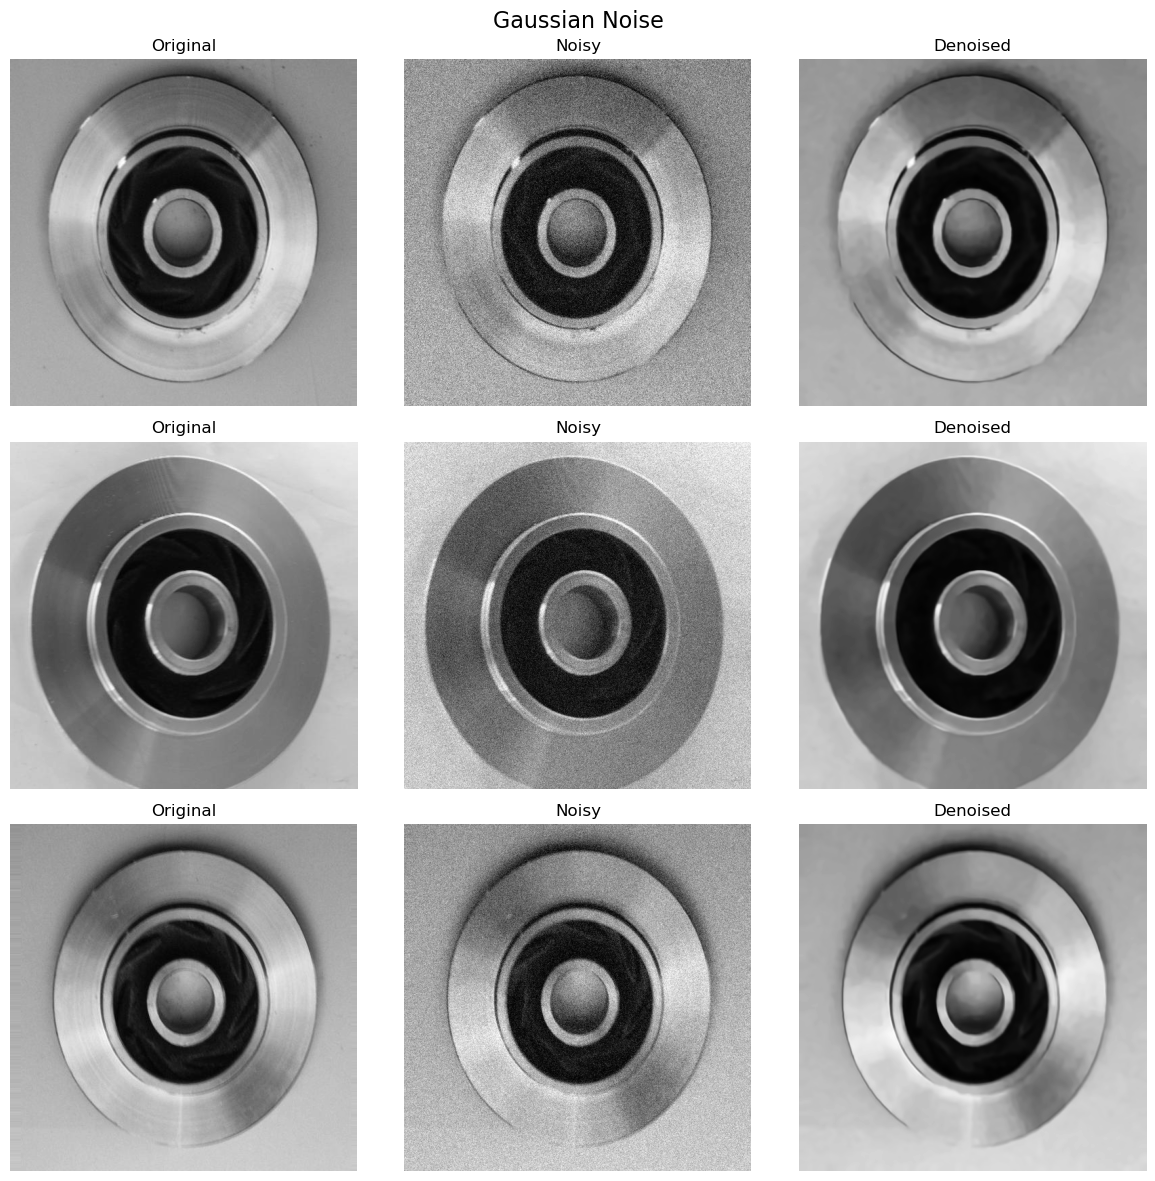

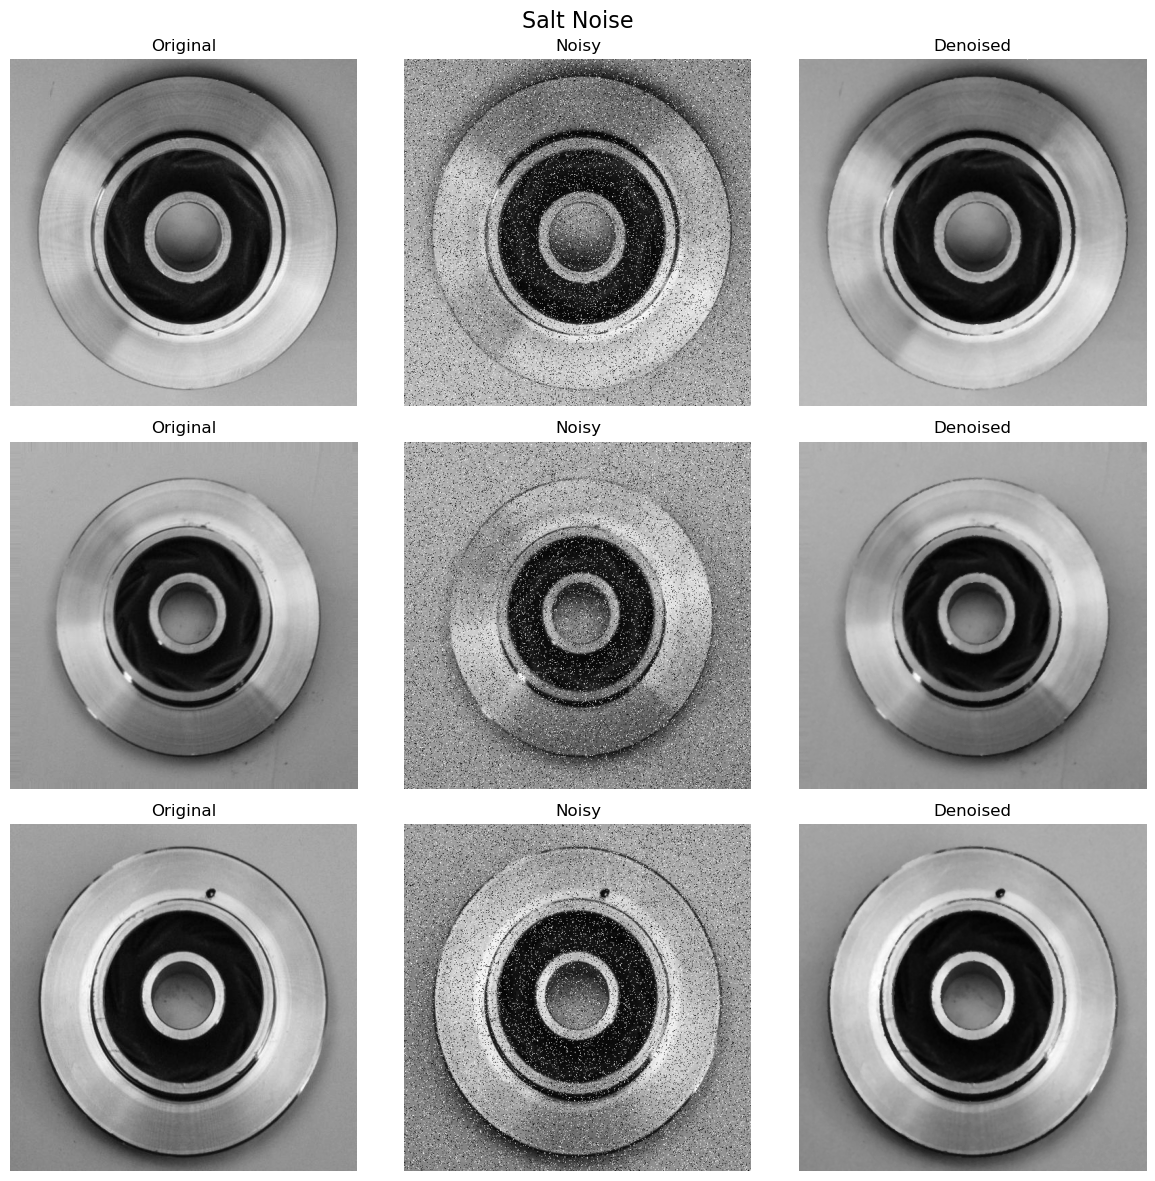

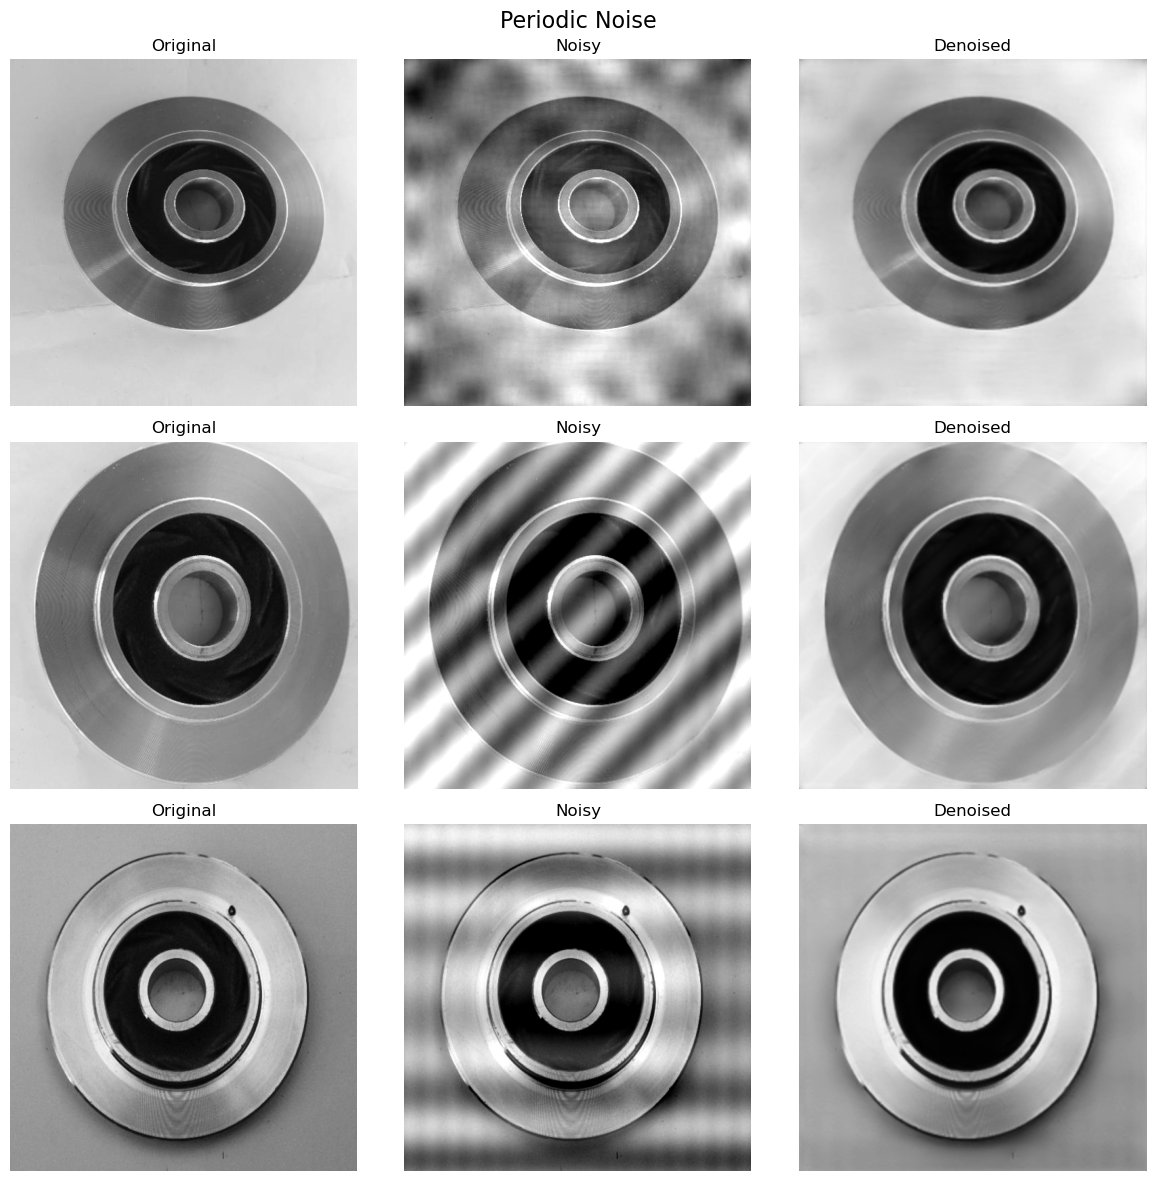

In [ ]:
df = pd.read_excel("./datasets/Labels.xlsx")

noise_column = "Noise Type"
image_column = "Denoise Image"
noisy_column = "Noisy Image"

dataset_folder = "./datasets/Dataset2"

noise_types = ["Gaussian", "Salt", "Periodic"]

random.seed(1)

for noise_type in noise_types:

    noise_df = df[df[noise_column].astype(str).str.strip().str.lower() == noise_type.lower()]

    valid_rows = []

    for _, row in noise_df.iterrows():

        clean_path = os.path.join(dataset_folder, str(row[image_column]))
        noisy_path = os.path.join(dataset_folder, str(row[noisy_column]))

        denoised_filename = os.path.basename(str(row[noisy_column]))
        denoised_path = os.path.join(dataset_folder, "Denoised", denoised_filename)

        if (os.path.exists(clean_path) and os.path.exists(noisy_path) and os.path.exists(denoised_path)):
            valid_rows.append(row)


    selected_rows = random.sample(valid_rows, min(3, len(valid_rows)))

    fig, axes = plt.subplots(3, 3, figsize=(12, 12))
    fig.suptitle(f"{noise_type} Noise", fontsize=16)

    for i, row in enumerate(selected_rows):

        clean_path = os.path.join(dataset_folder, str(row[image_column]))
        noisy_path = os.path.join(dataset_folder, str(row[noisy_column]))

        denoised_filename = os.path.basename(str(row[noisy_column]))
        denoised_path = os.path.join(dataset_folder, "Denoised", denoised_filename)

        clean_image = cv2.imread(clean_path, cv2.IMREAD_GRAYSCALE)
        noisy_image = cv2.imread(noisy_path, cv2.IMREAD_GRAYSCALE)
        denoised_image = cv2.imread(denoised_path, cv2.IMREAD_GRAYSCALE)

        if clean_image is None or noisy_image is None or denoised_image is None:
            print(f"Could not load image: {denoised_filename}")
            continue

        height, width = clean_image.shape
        noisy_image = cv2.resize(noisy_image, (width, height))
        denoised_image = cv2.resize(denoised_image, (width, height))

        axes[i, 0].imshow(clean_image, cmap="gray")
        axes[i, 0].set_title("Original")

        axes[i, 1].imshow(noisy_image, cmap="gray")
        axes[i, 1].set_title("Noisy")

        axes[i, 2].imshow(denoised_image, cmap="gray")
        axes[i, 2].set_title("Denoised")

        for j in range(3):
            axes[i, j].axis("off")

    for i in range(len(selected_rows), 3):
        for j in range(3):
            axes[i, j].axis("off")

    plt.tight_layout()
    plt.show()